In [22]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [23]:
class Value:

    def __init__(self, data, _children=(), _op='', label =''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward

        return out

    def __radd__(self, other): # other + self
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward

        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += other * self.data ** (other - 1) * out.grad # power rule then chain rule
        out._backward = _backward

        return out

    def __rmul__(self, other): # other * self
        return self * other

    def __truediv__(self, other): # self / other
        return self * other**-1

    def __neg__(self): # -self
        return self *-1

    def __sub__(self, other): # self - other
        return self + (-other)

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data 
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


In [24]:
from graphviz import Digraph

def trace(root):
    # used to build a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = Left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f } " % (n.label, n.data, n.grad ), shape='record')
        if n._op:
            #if this value is a result of some operation, create an op node for it
            dot.node(name= uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [25]:
# inputs x1, x2
x1 = Value(2.0, label ='x1')
x2 = Value(0.0, label ='x2')

# weights w1,w2
w1 = Value(-3.0, label ='w1')
w2 = Value(1.0, label ='w2')

# bias of the neuron
b = Value(6.8813735870195432, label ='b')

# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

o = n.tanh(); o.label = 'o'
o.backward()

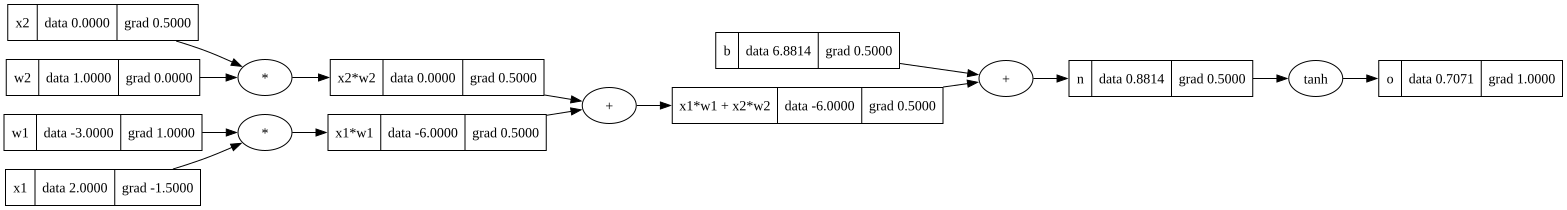

In [26]:
draw_dot(o)

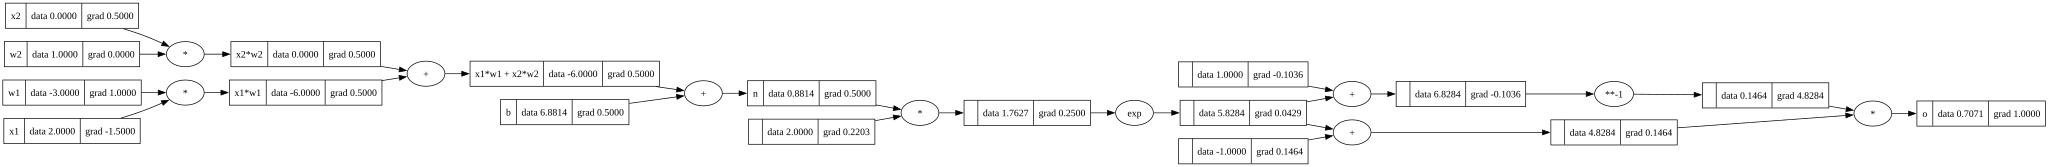

In [27]:
# inputs x1, x2
x1 = Value(2.0, label ='x1')
x2 = Value(0.0, label ='x2')

# weights w1,w2
w1 = Value(-3.0, label ='w1')
w2 = Value(1.0, label ='w2')

# bias of the neuron
b = Value(6.8813735870195432, label ='b')

# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
# ----
e = (2*n).exp()
o = (e - 1) / (e + 1)
# ----
o.label = 'o'
o.backward()
draw_dot(o)

In [28]:
import torch

In [29]:
x1 = torch.Tensor([2.0]).double()                   ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                   ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()                  ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                   ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()     ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [30]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()] # same as code bellow but list comprehention in python
        
        # params = []
        # for neuron in self.neurons:
        #     ps = neuron.parameters()
        #     params.extend(ps)
        # return params

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    

In [33]:
n.parameters()

[value(data=0.882903226316142),
 value(data=0.7021192865708243),
 value(data=0.7577395853758497),
 value(data=0.12499765755982062),
 value(data=-0.9345532255901698),
 value(data=-0.917080014745169),
 value(data=-0.6494402882736015),
 value(data=0.7269344153214345),
 value(data=-0.9776529616751497),
 value(data=0.6650971526002092),
 value(data=0.9909696059811277),
 value(data=0.3419006707069068),
 value(data=0.17746566894412985),
 value(data=-0.1254132274252966),
 value(data=-0.019938547068662382),
 value(data=-0.5382898774751967),
 value(data=0.2262883120485999),
 value(data=-0.09743742817266043),
 value(data=0.9968562821132079),
 value(data=0.3661336550357912),
 value(data=-0.7456187061459001),
 value(data=0.02967941403960994),
 value(data=0.7903181030381097),
 value(data=-0.2878836178479649),
 value(data=-0.8155535655226314),
 value(data=-0.17888558254539833),
 value(data=0.9342484283258234),
 value(data=-0.07374764969010905),
 value(data=-0.8605905874197355),
 value(data=0.447604044

In [32]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4,4,1])
n(x)

value(data=0.5403528046538092)

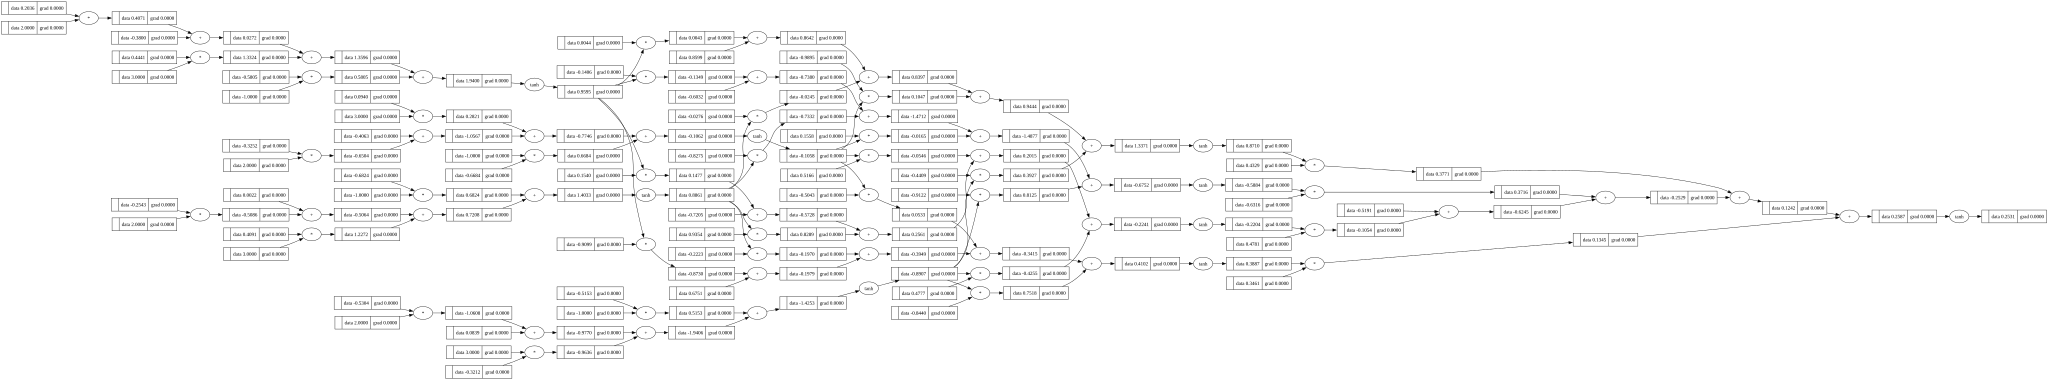

In [15]:
draw_dot(n(x))

In [ ]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

[value(data=0.5403528046538092),
 value(data=0.7293867988182078),
 value(data=-0.26479870947029804),
 value(data=0.4568026487459771)]

In [ ]:
ypred = [n(x) for x in xs]
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

value(data=4.037638544122233)

In [42]:
ypred = [n(x) for x in xs]
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

value(data=3.9470825362551984)

In [37]:
loss.backward()

In [38]:
n.layers[0].neurons[0].w[0].grad

-0.17362459331007798

In [39]:
n.layers[0].neurons[0].w[0].data

0.882903226316142

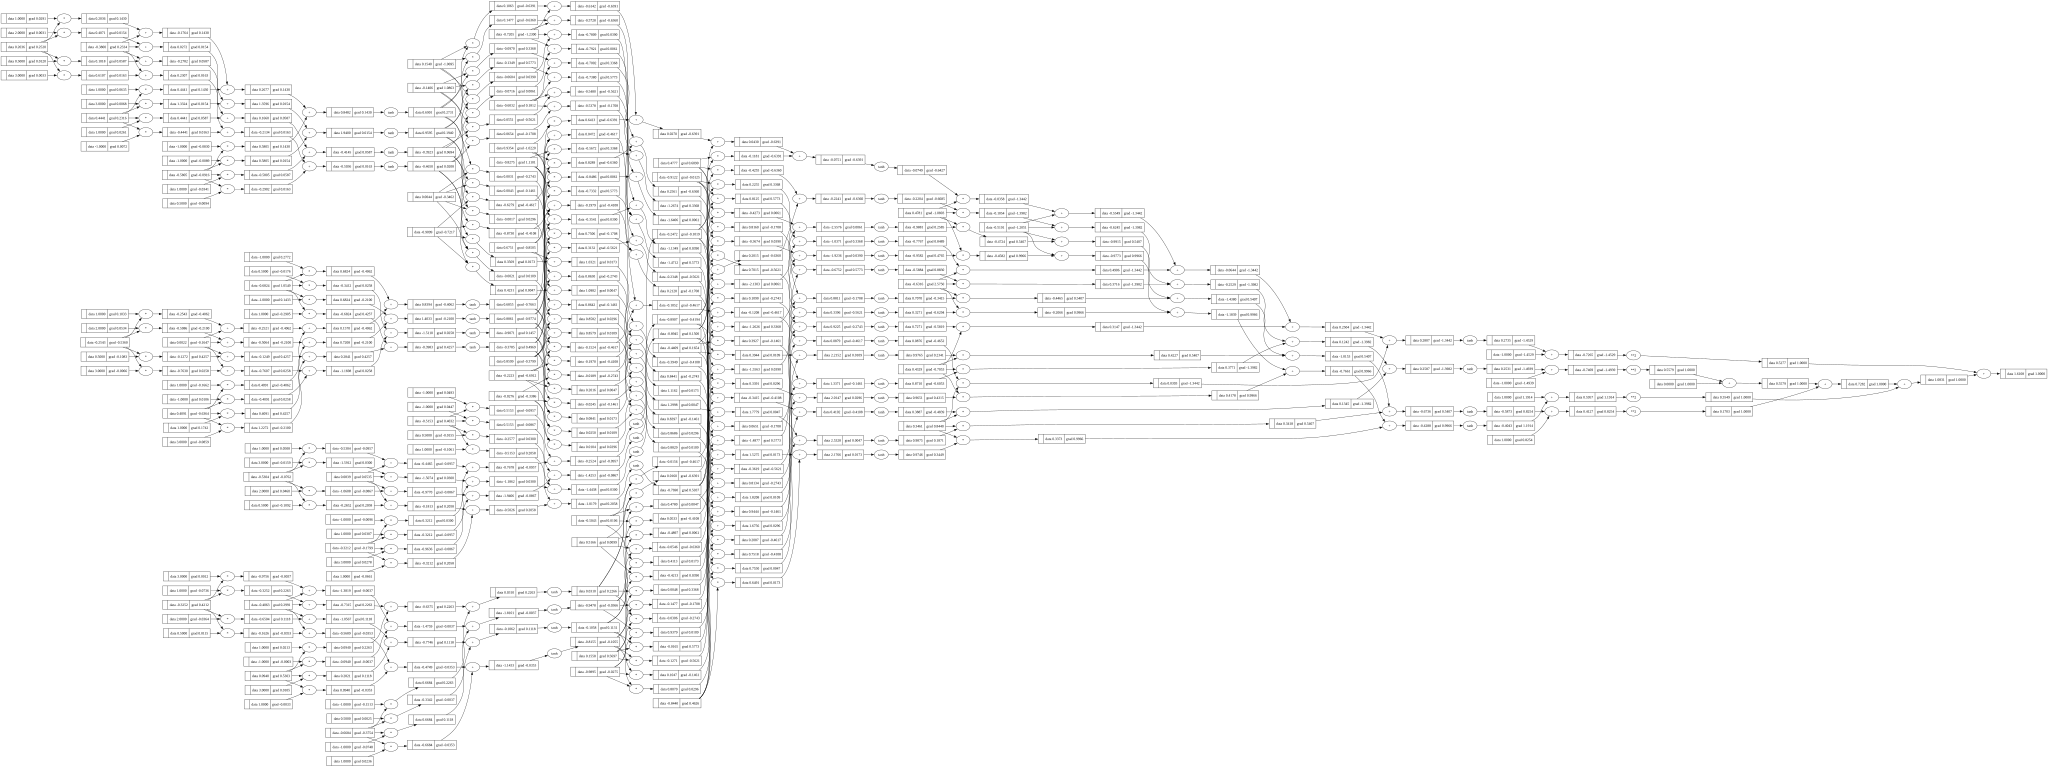

In [20]:
draw_dot(loss)

In [40]:
for p in n.parameters():
    p.data += -0.01 * p.grad 

In [41]:
n.layers[0].neurons[0].w[0].data

0.8846394722492428